# Module 4 — Task 3: Customer prioritisation and the executive question

**Business problem (brief, verbatim):**
> NovaFin wants to reduce customer attrition. Management asks: Which customers should relationship managers prioritize for retention?

**Task 3 (brief, verbatim):**
> **Task 3 — Customer prioritization.** Create four groups:
>
> | | Low Churn | High Churn |
> | --- | --- | --- |
> | **High CLV** | Protect | Priority retention |
> | **Low CLV** | Maintain | Low-cost intervention |
>
> **Executive question:** If NovaFin can contact only 1,000 customers, which customers should it target?

**Where this task sits:** churn prediction (Task 1) → customer lifetime value (Task 2) → **the four groups and the 1,000 customers (this task)**.

**What it receives:**

| From | File | How it is treated |
| --- | --- | --- |
| Task 1 | `FINAL_M4_T1_churn_scores.csv`: each customer's chance of churn | **No better than chance:** no model or bank rule beat random. Used to form the groups as the brief asks, with each group's actual churn shown beside it |
| Task 2 | `FINAL_M4_T2_customer_value.csv`: each customer's CLV | **Reliable:** an exact rule. The prioritisation rests on it |

**How the actual churn flag is used:** only to **check** the groups and the list after they are formed (a back-test: "if the bank had called these customers, how many who went on to leave would it have reached?"). It is never used to assign anyone, because a bank choosing whom to call can't know who will leave.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load the hand-offs |
| 2 | The cut-offs for High / Low, and how they are derived |
| 3 | The four groups, with their actual churn rates |
| 4 | What each group means for relationship managers |
| 5 | The executive question: the 1,000 customers to contact |
| 6 | Back-test: how the list compares with other ways of choosing |
| 7 | Is calling worth it? The break-even |
| 8 | What the results say |
| 9 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M4-15 hand-offs · M4-16 how the churn side is formed · M4-17 the cut-offs · M4-18 the 1,000 list and the break-even.

## 0. Setup
Works locally and in Google Colab. Runs in under a minute. Needs Tasks 1 and 2 to have run once.

In [1]:
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_04_customer_analytics"
TASK1_DIR, TASK2_DIR = MODULE_DIR / "outputs" / "task1", MODULE_DIR / "outputs" / "task2"
OUT_DIR = MODULE_DIR / "outputs" / "task3"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

from m04_data import load_customers
from m04_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, CHURN, STAY
apply_style()
plt.close("all")

SEED = 42
LAKH, CRORE = 1e5, 1e7
CONTACTS = 1_000                                   # the brief's executive question
GROUP_ORDER = ["Priority retention", "Protect", "Low-cost intervention", "Maintain"]
GROUP_COLOURS = {"Priority retention": CHURN, "Protect": BLUE, "Low-cost intervention": ORANGE, "Maintain": AQUA}
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Outputs go to: module_04_customer_analytics/outputs/task3


## 1. Load the hand-offs

In [2]:
cust = load_customers()[["Customer_ID", "Churn_Flag"]]
s1 = pd.read_csv(TASK1_DIR / "FINAL_M4_T1_churn_scores.csv")[["Customer_ID", "P_churn", "Churn predictable"]]
s2 = pd.read_csv(TASK2_DIR / "FINAL_M4_T2_customer_value.csv")[["Customer_ID", "Estimated_CLV"]]
df = cust.merge(s1, on="Customer_ID", validate="one_to_one").merge(s2, on="Customer_ID", validate="one_to_one")
assert len(df) == 5000 and df.notna().all().all()
df = df.rename(columns={"Estimated_CLV": "CLV"})
y, clv, p = df.Churn_Flag.to_numpy(), df.CLV.to_numpy(), df.P_churn.to_numpy()
CHURN_RATE = y.mean()
print(f"Customers {len(df):,};  churn scores: {df['Churn predictable'].iloc[0]}")
print(f"Actual churn rate {CHURN_RATE:.2%} ({y.sum()} of {len(y):,});  total CLV ₹{clv.sum() / CRORE:.2f} crore")

Customers 5,000;  churn scores: No: scores no better than chance
Actual churn rate 1.78% (89 of 5,000);  total CLV ₹32.80 crore


## 2. The cut-offs for High / Low, and how they are derived (decision M4-17)

| Cut-off | Value | How it is derived | Why |
| --- | --- | --- | --- |
| **High CLV** | the top 20% of CLV | 1,000 contacts ÷ 5,000 customers = 20% | The high-value groups (Protect and Priority retention) are then exactly as large as the calls available. The median would call 2,500 customers "High CLV", 2.5 times the calls |
| **High churn** | the model's chance of churn above the actual average, 1.78% | 89 churners ÷ 5,000 customers = 1.78% | "High churn" then reads as "the model rates this customer as more likely to leave than the typical customer", with no arbitrary percentage. The score is noise, so every cut gives near-equal actual churn |

In [3]:
CLV_CUT = np.quantile(clv, 1 - CONTACTS / len(clv))          # top 20% → 80th percentile
CHURN_CUT = CHURN_RATE                                          # the actual average chance
df["CLV level"] = np.where(clv >= CLV_CUT, "High CLV", "Low CLV")
df["Churn level"] = np.where(p > CHURN_CUT, "High churn", "Low churn")
df["Group"] = np.select([(df["CLV level"] == "High CLV") & (df["Churn level"] == "High churn"),
                         (df["CLV level"] == "High CLV") & (df["Churn level"] == "Low churn"),
                         (df["CLV level"] == "Low CLV") & (df["Churn level"] == "High churn")],
                        ["Priority retention", "Protect", "Low-cost intervention"], default="Maintain")
print(f"High CLV: CLV ≥ ₹{CLV_CUT:,.0f} (top {CONTACTS / len(clv):.0%} = {CONTACTS:,} ÷ {len(clv):,})")
print(f"High churn: chance of churn above {CHURN_CUT:.2%} (= {y.sum()} ÷ {len(y):,});  customers above it: {(p > CHURN_CUT).sum():,}")

High CLV: CLV ≥ ₹92,963 (top 20% = 1,000 ÷ 5,000)
High churn: chance of churn above 1.78% (= 89 ÷ 5,000);  customers above it: 2,132


## 3. The four groups, with their actual churn rates (decision M4-16)

Each group is formed only from the model's chance of churn and CLV. Its **actual** churn rate (the bank's data) is shown beside it, with a 95% range, to check whether "High churn" really churns more.

```text
Chi-square test across the four groups: do their actual churn rates differ by more than chance?  (p < 0.05 → yes)
```

In [4]:
def group_table(t: pd.DataFrame) -> pd.DataFrame:
    g = t.groupby("Group")
    out = pd.DataFrame({"Customers": g.size(), "CLV (₹ crore)": g.CLV.sum() / CRORE, "Share of all CLV": g.CLV.sum() / t.CLV.sum(),
                        "Average CLV (₹)": g.CLV.mean(), "Average chance of churn (model)": g.P_churn.mean(),
                        "Actual leavers": g.Churn_Flag.sum(), "Actual churn rate": g.Churn_Flag.mean()}).reindex(GROUP_ORDER)
    r = np.array([proportion_confint(k, n, method="wilson") for k, n in zip(out["Actual leavers"], out.Customers)])
    out["95% low"], out["95% high"] = r[:, 0], r[:, 1]
    out["CLV of leavers (₹ lakh)"] = t[t.Churn_Flag == 1].groupby("Group").CLV.sum().reindex(GROUP_ORDER).fillna(0) / LAKH
    return out


groups = group_table(df)
p_groups = stats.chi2_contingency(pd.crosstab(df.Group, df.Churn_Flag))[1]
p_churn_axis = stats.chi2_contingency(pd.crosstab(df["Churn level"], df.Churn_Flag))[1]
hc = df["Churn level"] == "High churn"
print(f"Do the four groups churn differently? chi-square p = {p_groups:.2f}")
print(f"High vs Low churn level (all customers): actual churn {y[hc].mean():.2%} vs {y[~hc].mean():.2%}, p = {p_churn_axis:.2f}")
groups.style.format({"Customers": "{:,.0f}", "CLV (₹ crore)": "₹{:,.2f}", "Share of all CLV": "{:.0%}", "Average CLV (₹)": "₹{:,.0f}",
                     "Average chance of churn (model)": "{:.2%}", "Actual churn rate": "{:.2%}", "95% low": "{:.1%}",
                     "95% high": "{:.1%}", "CLV of leavers (₹ lakh)": "₹{:,.1f}"})

Do the four groups churn differently? chi-square p = 0.67
High vs Low churn level (all customers): actual churn 1.88% vs 1.71%, p = 0.74


,Customers,CLV (₹ crore),Share of all CLV,Average CLV (₹),Average chance of churn (model),Actual leavers,Actual churn rate,95% low,95% high,CLV of leavers (₹ lakh)
Group,,,,,,,,,,
Priority retention,278,₹3.88,12%,"₹139,736",2.93%,3,1.08%,0.4%,3.1%,₹4.4
Protect,722,₹9.90,30%,"₹137,131",1.17%,11,1.52%,0.9%,2.7%,₹14.3
Low-cost intervention,"1,854",₹7.76,24%,"₹41,882",2.24%,37,2.00%,1.5%,2.7%,₹15.8
Maintain,"2,146",₹11.25,34%,"₹52,427",1.45%,38,1.77%,1.3%,2.4%,₹21.5


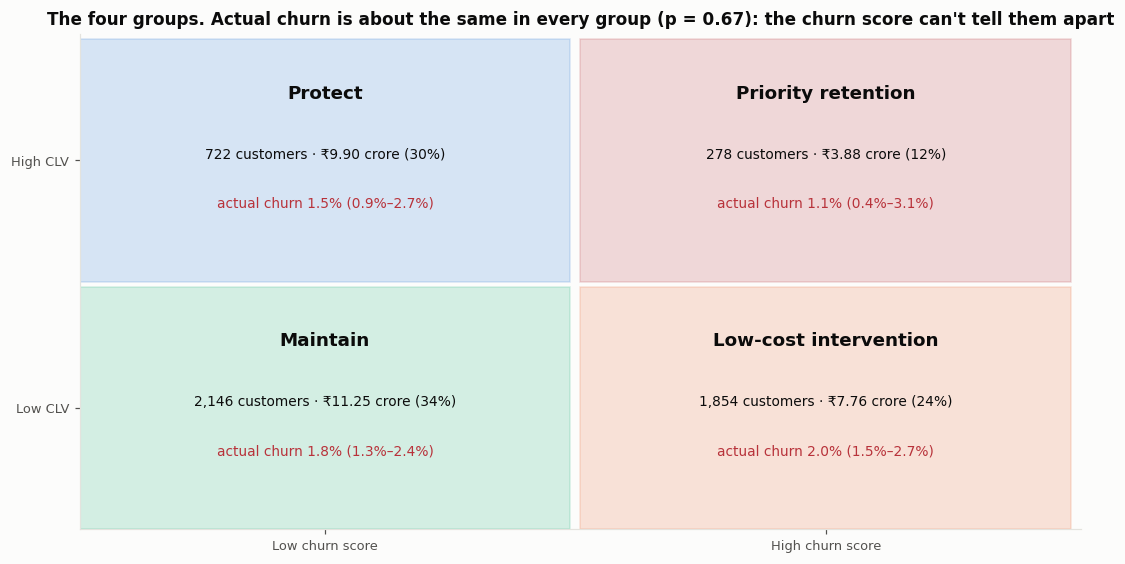

In [5]:
# Chart: the brief's 2 × 2 grid, each cell with its size, value and actual churn rate.
fig, ax = plt.subplots(figsize=(10, 5.2))
cells = {("High CLV", "Low churn"): "Protect", ("High CLV", "High churn"): "Priority retention",
         ("Low CLV", "Low churn"): "Maintain", ("Low CLV", "High churn"): "Low-cost intervention"}
for (row, col), name in cells.items():
    x, yy = (0 if col == "Low churn" else 1), (1 if row == "High CLV" else 0)
    g = groups.loc[name]
    ax.add_patch(plt.Rectangle((x, yy), 0.98, 0.98, color=GROUP_COLOURS[name], alpha=0.18))
    ax.text(x + 0.49, yy + 0.74, name, ha="center", fontsize=12, fontweight="bold", color=INK)
    ax.text(x + 0.49, yy + 0.50, f"{g.Customers:,.0f} customers · ₹{g['CLV (₹ crore)']:.2f} crore ({g['Share of all CLV']:.0%})",
            ha="center", fontsize=9)
    ax.text(x + 0.49, yy + 0.30, f"actual churn {g['Actual churn rate']:.1%} ({g['95% low']:.1%}–{g['95% high']:.1%})",
            ha="center", fontsize=9, color=CHURN)
ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([0.49, 1.49], ["Low churn score", "High churn score"])
ax.set_yticks([0.49, 1.49], ["Low CLV", "High CLV"]); ax.grid(False)
ax.set_title(f"The four groups. Actual churn is about the same in every group (p = {p_groups:.2f}): the churn score can't tell them apart")
fig.tight_layout(); save_chart(fig, "01_four_groups"); plt.show()

## 4. What each group means for relationship managers

The brief names the groups; the actions follow from them, adjusted for what the data shows (churn can't be told apart, value can):

| Group | Brief's intent | What it means on this data | Suggested action |
| --- | --- | --- | --- |
| **Priority retention** | High value, at risk: call first | High value; "at risk" can't be confirmed (the churn score is noise) | Personal call from the relationship manager, first in the queue |
| **Protect** | High value, safe: keep happy | High value; as likely to leave as anyone | Personal call too, after Priority retention: together they are the 1,000 |
| **Low-cost intervention** | Lower value, at risk | Lower value; risk not confirmed | Automated, cheap contact (email, app message) |
| **Maintain** | Lower value, safe | Lower value; as likely to leave as anyone | Business as usual |

## 5. The executive question: the 1,000 customers to contact (decision M4-18)

**The list:** the 1,000 highest-CLV customers, the **"Priority retention"** group first, then **"Protect"**, each ordered by CLV. Together these two groups are exactly the top 20% by CLV, so the four groups and the answer to the executive question fit together.

**Why value, not churn risk:** churn can't be foreseen from this data (Task 1), so every customer is about equally likely to leave. What differs is how much is lost when one does. That is CLV, which is reliable (Task 2).

In [6]:
contact = df[df.Group.isin(["Priority retention", "Protect"])].copy()
contact["Group order"] = contact.Group.map({"Priority retention": 0, "Protect": 1})
contact = contact.sort_values(["Group order", "CLV"], ascending=[True, False]).reset_index(drop=True)
contact["Call order"] = np.arange(1, len(contact) + 1)
assert len(contact) == CONTACTS


def why(r):
    """The reason for calling this customer, in plain words."""
    base = f"High value: CLV ₹{r.CLV:,.0f} (top 20%, at least ₹{CLV_CUT:,.0f})"
    if r.Group == "Priority retention":
        return base + f"; model rates churn above average ({r.P_churn:.2%} vs {CHURN_RATE:.2%}), though this score is no better than chance"
    return base + f"; model rates churn at or below average ({r.P_churn:.2%})"


contact["Why contact"] = contact.apply(why, axis=1)
print(f"The 1,000: {(contact.Group == 'Priority retention').sum()} Priority retention, then {(contact.Group == 'Protect').sum()} Protect")
print(f"They hold ₹{contact.CLV.sum() / CRORE:.2f} crore ({contact.CLV.sum() / clv.sum():.0%} of all value); CLV ₹{contact.CLV.min():,.0f} to ₹{contact.CLV.max():,.0f}")
contact[["Call order", "Customer_ID", "Group", "CLV", "P_churn", "Why contact"]].head(5)

The 1,000: 278 Priority retention, then 722 Protect
They hold ₹13.79 crore (42% of all value); CLV ₹93,019 to ₹439,367


,Call order,Customer_ID,Group,CLV,P_churn,Why contact
0,1,300294,Priority retention,439366.88,0.115776,"High value: CLV ₹439,367 (top 20%, at least ₹9..."
1,2,303835,Priority retention,399209.67,0.075195,"High value: CLV ₹399,210 (top 20%, at least ₹9..."
2,3,300415,Priority retention,315234.42,0.018489,"High value: CLV ₹315,234 (top 20%, at least ₹9..."
3,4,300310,Priority retention,298396.13,0.021066,"High value: CLV ₹298,396 (top 20%, at least ₹9..."
4,5,303324,Priority retention,297721.60,0.072881,"High value: CLV ₹297,722 (top 20%, at least ₹9..."


## 6. Back-test: how the list compares with other ways of choosing

**Back-test** = use what actually happened (`Churn_Flag`) to check a list chosen without it: "if the bank had called these 1,000, how many of the customers who went on to leave would it have reached, and how much value?"

| Measure | In plain words |
| --- | --- |
| Leavers reached | Of the 89 who left, how many were on the list |
| Value of leavers reached | How much of the lifetime value that walked out the list would have had the chance to save |
| Value contacted | How much of the book's value the list keeps in touch with |

Compared with: ranking by chance of churn × CLV ("expected value at risk"), by churn score only, and 500 random lists of 1,000 (luck's range).

In [7]:
def backtest(idx):
    idx = np.asarray(idx)[:CONTACTS]
    return {"Leavers reached (of 89)": int(y[idx].sum()), "Value of leavers reached (₹ lakh)": (clv[idx] * y[idx]).sum() / LAKH,
            "Share of value that left": (clv[idx] * y[idx]).sum() / (clv * y).sum(),
            "Value contacted (₹ crore)": clv[idx].sum() / CRORE, "Share of all value contacted": clv[idx].sum() / clv.sum()}


id_of = {cid: i for i, cid in enumerate(df.Customer_ID)}
lists = {"Recommended: the high-CLV groups": [id_of[c] for c in contact.Customer_ID],
         "Chance of churn × CLV": np.argsort(-(p * clv), kind="stable"),
         "Churn score only": np.argsort(-p, kind="stable")}
bt = pd.DataFrame({name: backtest(idx) for name, idx in lists.items()}).T
rng = np.random.default_rng(SEED)
rand = pd.DataFrame([backtest(rng.choice(len(df), CONTACTS, replace=False)) for _ in range(500)])
bt.loc["Random 1,000: average"] = rand.mean()
bt.loc["Random 1,000: 95% range high end"] = rand.quantile(0.975)
print(f"Value that left with the 89 leavers: ₹{(clv * y).sum() / LAKH:,.1f} lakh")
bt.style.format({"Leavers reached (of 89)": "{:.1f}", "Value of leavers reached (₹ lakh)": "₹{:,.1f}", "Share of value that left": "{:.0%}",
                 "Value contacted (₹ crore)": "₹{:,.2f}", "Share of all value contacted": "{:.0%}"})

Value that left with the 89 leavers: ₹56.0 lakh


,Leavers reached (of 89),Value of leavers reached (₹ lakh),Share of value that left,Value contacted (₹ crore),Share of all value contacted
Recommended: the high-CLV groups,14.0,₹18.7,33%,₹13.79,42%
Chance of churn × CLV,16.0,₹17.5,31%,₹11.96,36%
Churn score only,15.0,₹8.5,15%,₹5.82,18%
"Random 1,000: average",17.7,₹11.2,20%,₹6.57,20%
"Random 1,000: 95% range high end",25.0,₹17.4,31%,₹6.83,21%


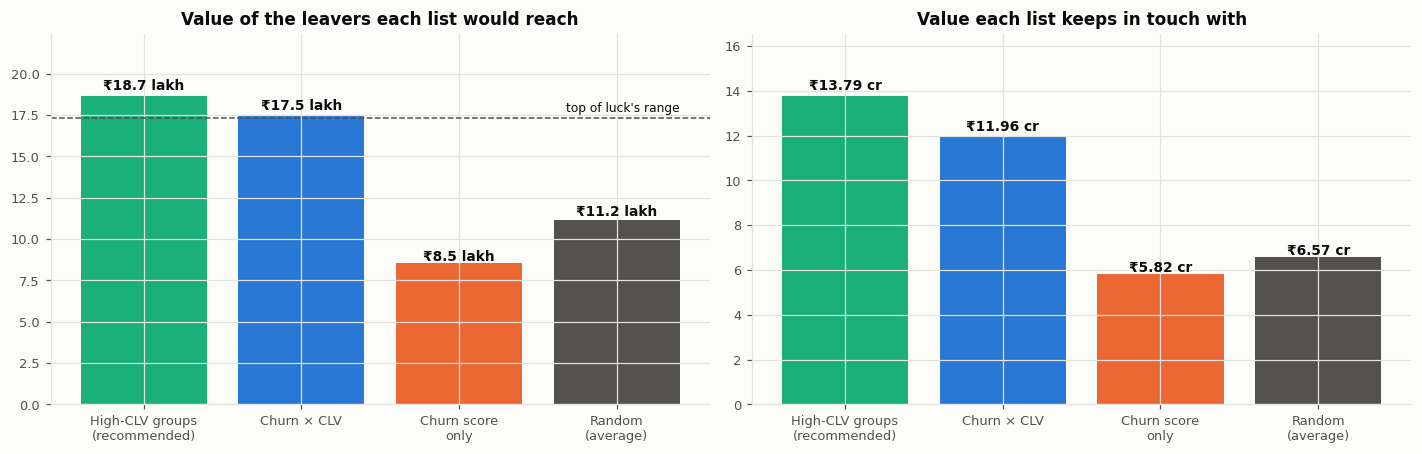

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = ["Recommended: the high-CLV groups", "Chance of churn × CLV", "Churn score only", "Random 1,000: average"]
cols = [AQUA, BLUE, ORANGE, INK_2]
labels = ["High-CLV groups\n(recommended)", "Churn × CLV", "Churn score\nonly", "Random\n(average)"]
for ax, col, title, fmt in [(axes[0], "Value of leavers reached (₹ lakh)", "Value of the leavers each list would reach", "₹{:.1f} lakh"),
                            (axes[1], "Value contacted (₹ crore)", "Value each list keeps in touch with", "₹{:.2f} cr")]:
    v = bt.loc[names, col]
    ax.bar(labels, v, color=cols)
    for i, val in enumerate(v):
        ax.text(i, val * 1.02, fmt.format(val), ha="center", fontsize=9, fontweight="bold")
    if col.startswith("Value of leavers"):
        ax.axhline(bt.loc["Random 1,000: 95% range high end", col], color=INK_2, ls="--", lw=1)
        ax.text(3.4, bt.loc["Random 1,000: 95% range high end", col] * 1.02, "top of luck's range", ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylim(0, v.max() * 1.2)
fig.tight_layout(); save_chart(fig, "02_backtest"); plt.show()

## 7. Is calling worth it? The break-even (decision M4-18)

**The success rate can't be predicted from this data:** the file has no record of past calls or offers. Any figure would be our assumption. So instead of assuming one, the break-even works out **the success rate calls would need** to be worth their cost:

```text
Expected loss if the bank doesn't call = chance of leaving × CLV          (chance = the actual 1.78%: nothing tells customers apart)
Value of a call                         = success rate × expected loss       (the share of would-be leavers the call keeps)
A call pays off if:  success rate × expected loss  >  cost of the call
→ success rate needed  =  cost of the call ÷ expected loss
```

**Worked example:** the lowest-value customer on the list (CLV ₹93,019): expected loss = 1.78% × ₹93,019 = ₹1,656. A ₹500 call must keep at least 500 ÷ 1,656 = 30% of would-be leavers. That is the bar, not a claim that calls *do* succeed 30% of the time.

The bank supplies its call cost and its experience of success; the table shows the bar to clear. To measure the real success rate: call a random half of a test group, leave the other half, and compare who leaves (a randomised test).

In [9]:
costs = [100, 250, 500, 1000]
who = {"Lowest-value customer on the list": contact.CLV.min(), "Median customer on the list": contact.CLV.median(),
       "Average customer on the list": contact.CLV.mean()}
be = pd.DataFrame({name: {f"Call costs ₹{c:,}": min(c / (CHURN_RATE * v), 9.99) for c in costs} for name, v in who.items()}).T
be.insert(0, "Expected loss if not called (₹)", [CHURN_RATE * v for v in who.values()])
be.insert(0, "CLV (₹)", list(who.values()))
campaign_loss = CHURN_RATE * contact.CLV.sum()
print(f"Whole list: expected loss if nobody is called = {CHURN_RATE:.2%} × ₹{contact.CLV.sum() / CRORE:.2f} crore = ₹{campaign_loss / LAKH:,.1f} lakh")
for c in costs:
    print(f"  at ₹{c:,} a call, 1,000 calls cost ₹{c * CONTACTS / LAKH:,.1f} lakh → calls must keep at least {c * CONTACTS / campaign_loss:.0%} of would-be leavers")
be.style.format({"CLV (₹)": "₹{:,.0f}", "Expected loss if not called (₹)": "₹{:,.0f}"} | {f"Call costs ₹{c:,}": "{:.0%}" for c in costs})

Whole list: expected loss if nobody is called = 1.78% × ₹13.79 crore = ₹24.5 lakh
  at ₹100 a call, 1,000 calls cost ₹1.0 lakh → calls must keep at least 4% of would-be leavers
  at ₹250 a call, 1,000 calls cost ₹2.5 lakh → calls must keep at least 10% of would-be leavers
  at ₹500 a call, 1,000 calls cost ₹5.0 lakh → calls must keep at least 20% of would-be leavers
  at ₹1,000 a call, 1,000 calls cost ₹10.0 lakh → calls must keep at least 41% of would-be leavers


,CLV (₹),Expected loss if not called (₹),Call costs ₹100,Call costs ₹250,Call costs ₹500,"Call costs ₹1,000"
Lowest-value customer on the list,"₹93,019","₹1,656",6%,15%,30%,60%
Median customer on the list,"₹122,389","₹2,179",5%,11%,23%,46%
Average customer on the list,"₹137,855","₹2,454",4%,10%,20%,41%


## 8. What the results say

### The four groups (steps 2–3)

| Group | Customers | CLV | Share of all CLV | Model's average chance of churn | Actual churn (95% range) |
| --- | --- | --- | --- | --- | --- |
| **Priority retention** (High CLV, High churn score) | 278 | ₹3.88 crore | 12% | 2.93% | 1.08% (0.4–3.1%) |
| **Protect** (High CLV, Low churn score) | 722 | ₹9.90 crore | 30% | 1.17% | 1.52% (0.9–2.7%) |
| **Low-cost intervention** (Low CLV, High churn score) | 1,854 | ₹7.76 crore | 24% | 2.24% | 2.00% (1.5–2.7%) |
| **Maintain** (Low CLV, Low churn score) | 2,146 | ₹11.25 crore | 34% | 1.45% | 1.77% (1.3–2.4%) |

- **The four groups churn about the same** (chi-square p = 0.67). "High churn score" customers churn 1.88% against 1.71% for the rest (p = 0.74).
- **"Priority retention" churns least of all (1.08%),** although the model rated it riskiest (2.93%). That is the noise in the churn score from Task 1 showing through.
- **So the groups differ in value, not in risk.** The High-CLV groups hold 42% of all value in 20% of customers.

### The 1,000 customers to contact (step 5)
- **The 278 "Priority retention" customers first, then the 722 "Protect" customers, each ordered by CLV:** exactly the 1,000 highest-value customers, CLV ₹93,019 to ₹4,39,367, holding **₹13.79 crore (42% of all value)**.
- **Why value, not risk:** every customer is about equally likely to leave (Task 1), so what differs is how much is lost when one does.

### Back-test: would the list have worked? (step 6)

| Way of choosing 1,000 | Leavers reached (of 89) | Value of those leavers (of ₹56.0 lakh that left) | Value contacted |
| --- | --- | --- | --- |
| **Recommended: the high-CLV groups** | 14 | **₹18.7 lakh (33%)** | **₹13.79 crore (42%)** |
| Chance of churn × CLV | 16 | ₹17.5 lakh (31%) | ₹11.96 crore (36%) |
| Churn score only | 15 | ₹8.5 lakh (15%) | ₹5.82 crore (18%) |
| Random 1,000 (average of 500) | 17.7 | ₹11.2 lakh (95% range up to ₹17.4 lakh) | ₹6.57 crore (20%) |

- **No list reaches more leavers than random calling.** Who leaves can't be foreseen (Task 1).
- **The recommended list reaches the most value**, just above the top of luck's range. That isn't skill at spotting leavers: high-value customers are simply worth more when they leave. It also keeps the bank in touch with 42% of all value.
- **Adding the churn score only dilutes the list:** ranking by chance × CLV covers less value, and the churn score alone does worse than random.

### Is calling worth it? (step 7)
- **No success rate or call cost is assumed** (the data has no record of past calls). The break-even gives the share of would-be leavers a call must keep to pay for itself:

| Customer on the list | CLV | Expected loss if not called (1.78% × CLV) | ₹100 call | ₹250 call | ₹500 call | ₹1,000 call |
| --- | --- | --- | --- | --- | --- | --- |
| Lowest-value | ₹93,019 | ₹1,656 | 6% | 15% | 30% | 60% |
| Median | ₹1,22,389 | ₹2,179 | 5% | 11% | 23% | 46% |
| Average | ₹1,37,855 | ₹2,454 | 4% | 10% | 20% | 41% |

- **Whole list:** expected loss if nobody is called = 1.78% × ₹13.79 crore = **₹24.5 lakh**. 1,000 calls at ₹500 cost ₹5 lakh, so they pay off if they keep at least 20% of would-be leavers.
- **Next step for the bank:** a randomised test (call a random half of a test group, compare who leaves) to measure the real success rate before scaling.

## 9. Save the outputs

- **`FINAL_M4_T3_contact_list.csv`: the answer to the executive question.** The 1,000 customers in call order, each with group, CLV, chance of churn and the reason in words. The actual churn flag is included as a back-test column only.
- **`customer_groups.csv`:** every customer's group.
- The charts above and `key_numbers.json`.

In [10]:
out_list = contact[["Call order", "Customer_ID", "Group", "CLV", "P_churn", "Why contact"]].copy()
out_list["Left (back-test only, not known when calling)"] = np.where(contact.Churn_Flag == 1, "Yes", "No")
out_list = out_list.rename(columns={"CLV": "CLV (₹)", "P_churn": "Chance of churn (no better than chance)"})
save_table(out_list.round(4), "FINAL_M4_T3_contact_list")
save_table(df[["Customer_ID", "Group", "CLV level", "Churn level", "CLV", "P_churn"]].round(4), "customer_groups")


def r4(v):
    return round(float(v), 4)


key = {"clv_cut": round(float(CLV_CUT), 2), "churn_cut": r4(CHURN_CUT), "groups_p": r4(p_groups),
       "groups": {g: {"customers": int(groups.loc[g, "Customers"]), "clv_crore": round(float(groups.loc[g, "CLV (₹ crore)"]), 2),
                      "actual_churn": r4(groups.loc[g, "Actual churn rate"])} for g in GROUP_ORDER},
       "backtest": {n: {k: r4(v) for k, v in bt.loc[n].items()} for n in bt.index},
       "campaign_expected_loss_lakh": round(float(campaign_loss / LAKH), 2)}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_04_customer_analytics/outputs/task3
['01_four_groups.png', '02_backtest.png', 'FINAL_M4_T3_contact_list.csv', 'customer_groups.csv', 'key_numbers.json']


## What goes to Module 9: Wealth management in the standard fields (decision M4-20)
Module 9 compares every business on the same fields. This module gives Wealth management its **fee income per ₹ of client balances**, net of churn, and a bad year: a market fall of 20% (balances and fees fall with it) with churn twice as high. **How much client money ₹1 of NovaFin's capital brings in is not in the data;** Wealth's return per ₹ of capital comes from Module 1's Wealth unit.

In [11]:
M9_COLS = ["Category", "What NovaFin would put money into", "Return per ₹ deployed (% a year)", "Return range (% a year)",
           "Bad-year result per ₹ (% a year)", "How the bad year is defined", "Capacity (₹ crore)", "Evidence strength",
           "How fast the money can come back", "Data gap or assumption", "Controls", "Detail tab", "Detail column(s)", "Decision"]
s1_ = pd.read_csv(MODULE_DIR / "outputs" / "task1" / "FINAL_M4_T1_churn_scores.csv"); s2_ = pd.read_csv(MODULE_DIR / "outputs" / "task2" / "FINAL_M4_T2_customer_value.csv")
fees = s2_["From investments (1.8%)"]; bal_crore = fees.sum() / 0.018 / 1e7
churn_loss = s2_.merge(s1_[["Customer_ID", "Churn_Flag"]], on="Customer_ID").query("Churn_Flag == 1")["From investments (1.8%)"].sum() / fees.sum()
net = 1.8 * (1 - churn_loss); bad = 1.8 * 0.8 * (1 - 2 * churn_loss)
m9_inputs = pd.DataFrame([{"Category": "Wealth management: fees on client balances", "What NovaFin would put money into": f"Wealth management (sample book: ₹{bal_crore:.1f} crore of client investment balances)",
    "Return per ₹ deployed (% a year)": round(net, 2), "Return range (% a year)": f"{bad:.2f} (bad year) to 1.80 (no churn), per ₹ of client balances",
    "Bad-year result per ₹ (% a year)": round(bad, 2), "How the bad year is defined": "Market fall of 20% (balances and fees fall with it) and churn twice as high",
    "Capacity (₹ crore)": round(bal_crore, 1), "Evidence strength": "Medium: fee yield read from the CLV formula (exact fit); churn can't be predicted",
    "How fast the money can come back": "Client money stays with clients; fees arrive yearly",
    "Data gap or assumption": "Per ₹ of client balances, not of NovaFin's capital; return per ₹ of capital comes from Module 1's Wealth unit (17.6% a year)",
    "Controls": "No model-driven retention until a randomised test; contact list for high-value customers", "Detail tab": "T2 customer value",
    "Detail column(s)": "From investments (1.8%), Churn_Flag (T1)", "Decision": "M4-20"}])[M9_COLS]
m9_inputs.to_csv(OUT_DIR / "module9_inputs.csv", index=False)
print(f"Wealth fee income: {net:.2f}% of client balances a year (bad year {bad:.2f}%); sample book ₹{bal_crore:.1f} crore")
display(m9_inputs.T)

Wealth fee income: 1.77% of client balances a year (bad year 1.39%); sample book ₹328.1 crore


,0
Category,Wealth management: fees on client balances
What NovaFin would put money into,Wealth management (sample book: ₹328.1 crore o...
Return per ₹ deployed (% a year),1.77
Return range (% a year),"1.39 (bad year) to 1.80 (no churn), per ₹ of c..."
Bad-year result per ₹ (% a year),1.39
How the bad year is defined,Market fall of 20% (balances and fees fall wit...
Capacity (₹ crore),328.1
Evidence strength,Medium: fee yield read from the CLV formula (e...
How fast the money can come back,Client money stays with clients; fees arrive y...
Data gap or assumption,"Per ₹ of client balances, not of NovaFin's cap..."
